# Cointegration pairs trading on US large caps, 2011-2026

**Sam Berman, University College Dublin**

This notebook runs the whole pipeline (`src/run_pipeline.py`) from cached raw
data and walks through the results. Every number in the README comes from the
tables produced here. Runtime: about 2-3 minutes (the cointegration tests on
5,455 pair-windows dominate).

Structure:
1. Data and data-quality screen
2. Pair selection: how many pairs are really cointegrated?
3. Portfolio results (BH vs uncorrected selection; OLS vs Kalman hedge)
4. Out-of-sample breakdown of cointegration
5. Sensitivity grid
6. Worked example, recomputed by hand

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import run_pipeline
from src.config import BASELINE, UNIVERSE, RESULTS_DIR, FIGURES_DIR
from src.data import load_prices, data_sources, large_moves

pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)

## 1. Data
Daily adjusted closes (splits and dividends) from Yahoo Finance via `yfinance`, cached in `data/raw/`.

In [2]:
prices = load_prices()
print(prices.shape, prices.index[0].date(), "to", prices.index[-1].date())
print("sources used:", sorted(set(data_sources().values())))
print("first valid date of late listings:")
print(prices.apply(lambda s: s.first_valid_index().date()).sort_values().tail(3))
pd.DataFrame({g: [", ".join(t)] for g, t in UNIVERSE.items()}, index=["tickers"]).T

(4227, 54) 2010-01-04 to 2026-10-22
sources used: ['yahoo']
first valid date of late listings:
MPC     2011-06-24
PSX     2012-04-12
PYPL    2015-07-06
dtype: object


,tickers
energy,"XOM, CVX, COP, EOG, OXY, SLB, HAL, VLO, MPC, PSX"
banks,"JPM, BAC, C, WFC, USB, PNC, GS, MS"
payments,"V, MA, AXP, COF, PYPL"
beverages,"KO, PEP, MNST, STZ, TAP, BF-B"
semis,"INTC, TXN, ADI, QCOM, NVDA, AMD, MU, AMAT, LRC..."
utilities,"DUK, SO, AEP, D, XEL, ED, NEE, WEC"
etf_commodity_fx,"EWA, EWC"
etf_gold,"GLD, GDX"
etf_europe,"EWG, EWQ"


Data-quality screen: daily moves larger than 25% in log terms. All of them
match known events rather than data errors: the oil and COVID crash of
9-18 March 2020, the Pfizer vaccine rally (VLO, 9 Nov 2020), earnings moves
(AMD 2016/2017, NVDA Nov 2016, PayPal Feb 2022, Intel Aug 2024), Constellation's
Modelo deal (STZ, Feb 2013) and Coca-Cola's stake in Monster (Aug 2014). The
COP/PSX spin-off (May 2012) is adjusted in Yahoo's series and does not appear
as a jump.

In [3]:
large_moves(prices)

,Date,ticker,log_return
0,2013-02-14,STZ,0.317
1,2014-08-15,MNST,0.266
2,2016-04-22,AMD,0.421
3,2016-11-11,NVDA,0.261
4,2017-05-02,AMD,-0.277
5,2020-03-09,COP,-0.286
6,2020-03-09,EOG,-0.386
7,2020-03-09,HAL,-0.472
8,2020-03-09,OXY,-0.734
9,2020-03-09,SLB,-0.320


## Run the pipeline
This regenerates every table in `results/` and every figure in `figures/`.

In [4]:
key = run_pipeline.main()
print(json.dumps(key["sample"], indent=1))

2026-10-23 15:04:59,864 prices (4227, 54), 2010-01-04 to 2026-10-22


2026-10-23 15:05:26,795 cointegration tests done (5455 pair-windows) in 27s


2026-10-23 15:05:30,212 main backtests done in 31s


2026-10-23 15:06:40,535 grid + robustness done in 101s


2026-10-23 15:06:42,787 pipeline finished in 103s


{
 "start": "2010-01-04",
 "end": "2026-10-22",
 "first_trade_day": "2011-01-03",
 "n_days": 3975,
 "n_years": 15.773809523809524,
 "n_tickers": 53,
 "requested_start": "2010-01-01",
 "requested_end_exclusive": "2026-10-23",
 "sources": [
  "yahoo"
 ]
}


## 2. Pair selection

Each 252-day formation window tests every within-industry pair (153-174 pairs
per window, 5,455 pair-windows in total) with Engle-Granger in both directions
and with Johansen's trace test. If no pair were cointegrated, directional
EG p-values would be uniform, so about 5% would fall below 0.05 by chance.

In [5]:
sel = key["selection"]
pd.Series(sel)

n_windows                         32.000
n_pair_tests                    5455.000
directional_reject_rate_5pct       0.082
storey_pi0                         0.895
max_p_reject_rate_5pct             0.047
johansen_reject_rate_5pct          0.122
n_bh_significant                   7.000
n_by_significant                   4.000
n_selected_bh                      7.000
n_selected_uncorrected           175.000
windows_with_no_bh_pair           26.000
dtype: float64

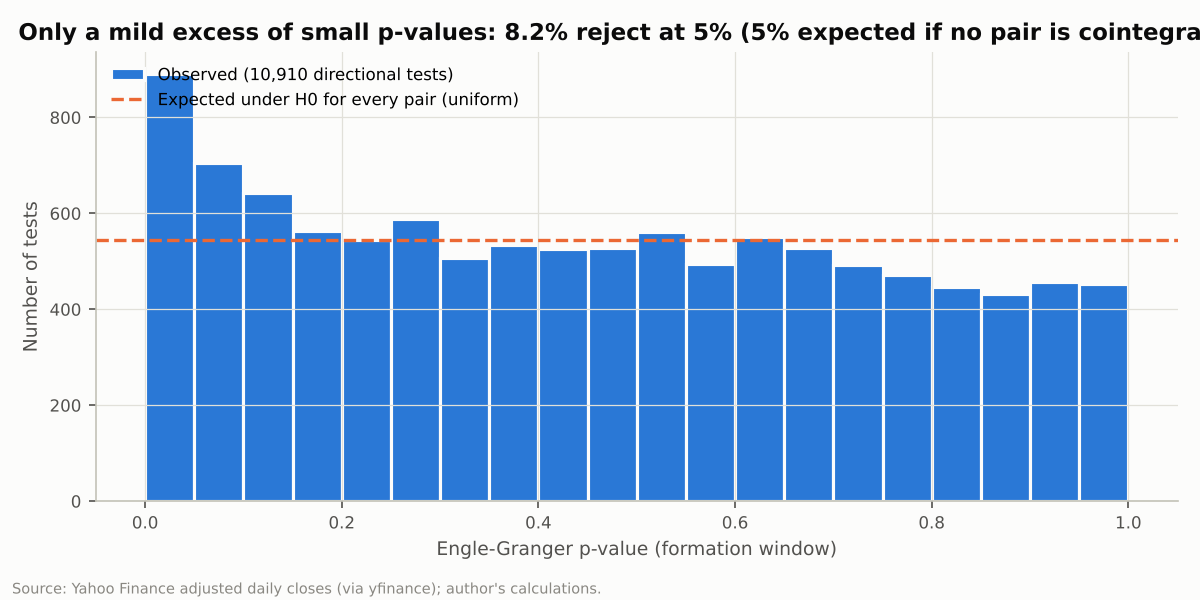

In [6]:
display(Image(FIGURES_DIR / "fig2_pvalue_histogram.png"))

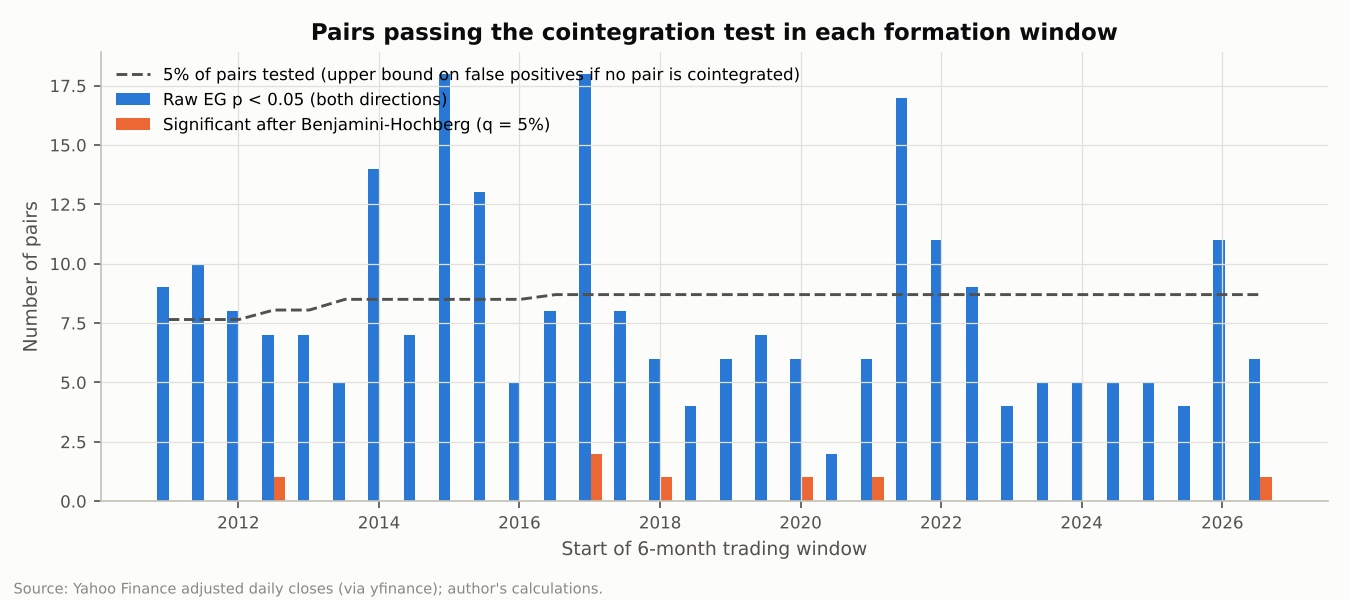

,trade_start,n_tested,n_raw_sig,n_bh_sig,n_selected_bh,n_selected_uncorrected
0,2011-01-03,153,9,0,0,5
1,2011-07-05,153,10,0,0,7
2,2012-01-03,153,8,0,0,5
3,2012-07-03,161,7,1,1,6
4,2013-01-04,161,7,0,0,6
5,2013-07-08,170,5,0,0,4
6,2014-01-06,170,14,0,0,10
7,2014-07-08,170,7,0,0,4
8,2015-01-06,170,18,0,0,15
9,2015-07-08,170,13,0,0,10


In [7]:
display(Image(FIGURES_DIR / "fig3_pairs_per_window.png"))
pd.read_csv(RESULTS_DIR / "selection_by_window.csv")[["trade_start", "n_tested", "n_raw_sig", "n_bh_sig", "n_selected_bh", "n_selected_uncorrected"]]

**Reading.** 8.2% of directional tests reject at 5%, against 5% expected
under the null. That is some evidence of cointegration in aggregate, but weak:
Storey's estimate of the share of true nulls is about 0.89. After the
Benjamini-Hochberg correction only 7 pair-windows survive in 32 windows, and 26
windows have no tradable pair at all. Johansen rejects 12% of the time, more
than EG; the Johansen trace test is known to over-reject in samples this short,
which is why it is used only as a confirmation filter.

## 3. Portfolio results (after costs, committed capital)

In [8]:
perf = pd.read_csv(RESULTS_DIR / "performance.csv", index_col=0)
cols = ["ann_return", "ann_vol", "sharpe", "t_stat", "p_value", "max_drawdown", "turnover",
        "n_trades", "hit_rate", "avg_holding_days", "time_in_market", "beta", "beta_p", "corr",
        "alpha_ann", "alpha_p"]
perf[cols + ["trade_t_p", "trade_wilcoxon_p", "window_t_p", "top2_share"]].T

,BH (pre-specified) / OLS,BH (pre-specified) / KALMAN,Uncorrected / OLS,Uncorrected / KALMAN,S&P 500 (SPY)
ann_return,0.004,0.020,-0.020,-0.021,1.409e-01
ann_vol,0.063,0.050,0.086,0.084,1.697e-01
sharpe,0.091,0.420,-0.190,-0.208,7.500e-01
t_stat,0.438,1.775,-0.798,-0.956,3.374e+00
p_value,0.661,0.076,0.425,0.339,7.405e-04
max_drawdown,-0.208,-0.121,-0.383,-0.391,-3.372e-01
turnover,2.539,3.777,10.250,12.326,NaN
n_trades,12.000,16.000,225.000,242.000,NaN
hit_rate,0.500,0.875,0.489,0.550,NaN
avg_holding_days,23.000,11.312,32.973,20.446,NaN


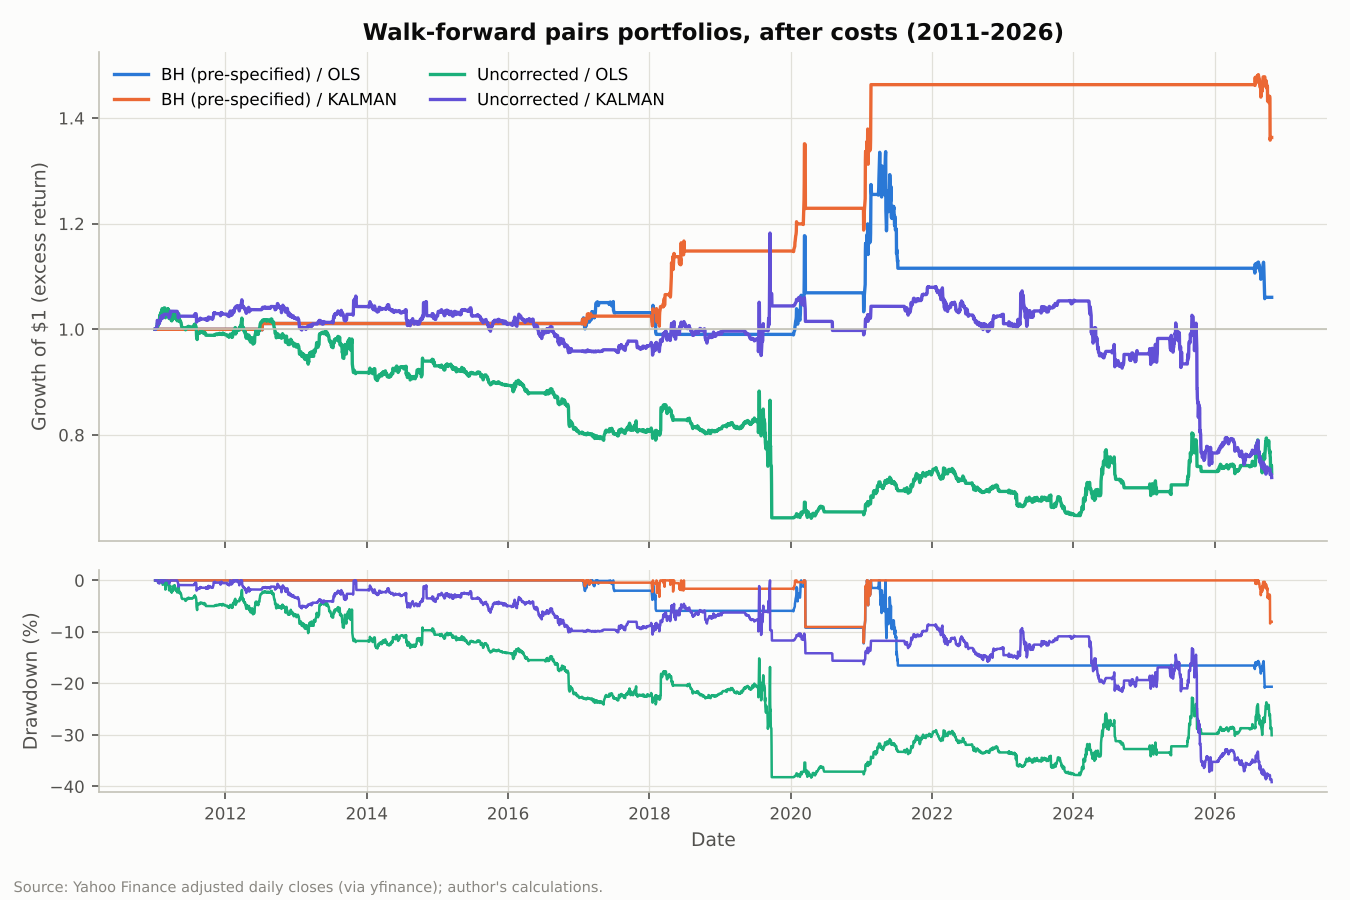

In [9]:
display(Image(FIGURES_DIR / "fig1_cumulative_returns.png"))

In [10]:
# Kalman minus OLS: mean daily return difference, Newey-West t-test
pd.read_csv(RESULTS_DIR / "kalman_vs_ols.csv")

,spec,ann_mean_diff,t_stat,p_value
0,BH (pre-specified),1.516e-02,1.463,0.143
1,Uncorrected,-9.803e-04,-0.045,0.964


## 4. Does cointegration survive out of sample, and what does a breakdown cost?

In [11]:
pd.read_csv(RESULTS_DIR / "breakdown.csv").set_index(["spec", "hedge"]).T

spec                       BH (pre-specified)         Uncorrected         
hedge                                     ols  kalman         ols   kalman
pair_windows                            7.000   7.000     175.000  175.000
pct_oos_adf_reject                      0.143   0.143       0.074    0.074
median_oos_z_sd                         1.454   1.454       1.466    1.466
pct_pairs_oos_z_sd_above_2              0.143   0.143       0.257    0.257
mean_frac_days_beyond_stop              0.135   0.135       0.195    0.195
median_signal_z_ac1                     0.934   0.879       0.959    0.902
mean_pnl_adf_reject                    -0.040   0.117       0.053   -0.003
mean_pnl_adf_no_reject                  0.025   0.038      -0.007   -0.009
n_adf_reject                            1.000   1.000      13.000   13.000
n_adf_no_reject                         6.000   6.000     162.000  162.000
n_trades                               12.000  16.000     225.000  242.000
n_stops                                 4.000   3.000     112.000   25.000
stop_rate                               0.333   0.188       0.498    0.103
stop_pnl_total                         -0.170  -0.158      -5.877   -1.278
nonstop_pnl_total                       0.281   0.502       5.374   -0.137
window_end_pnl_total                   -0.141   0.000       0.439   -0.599

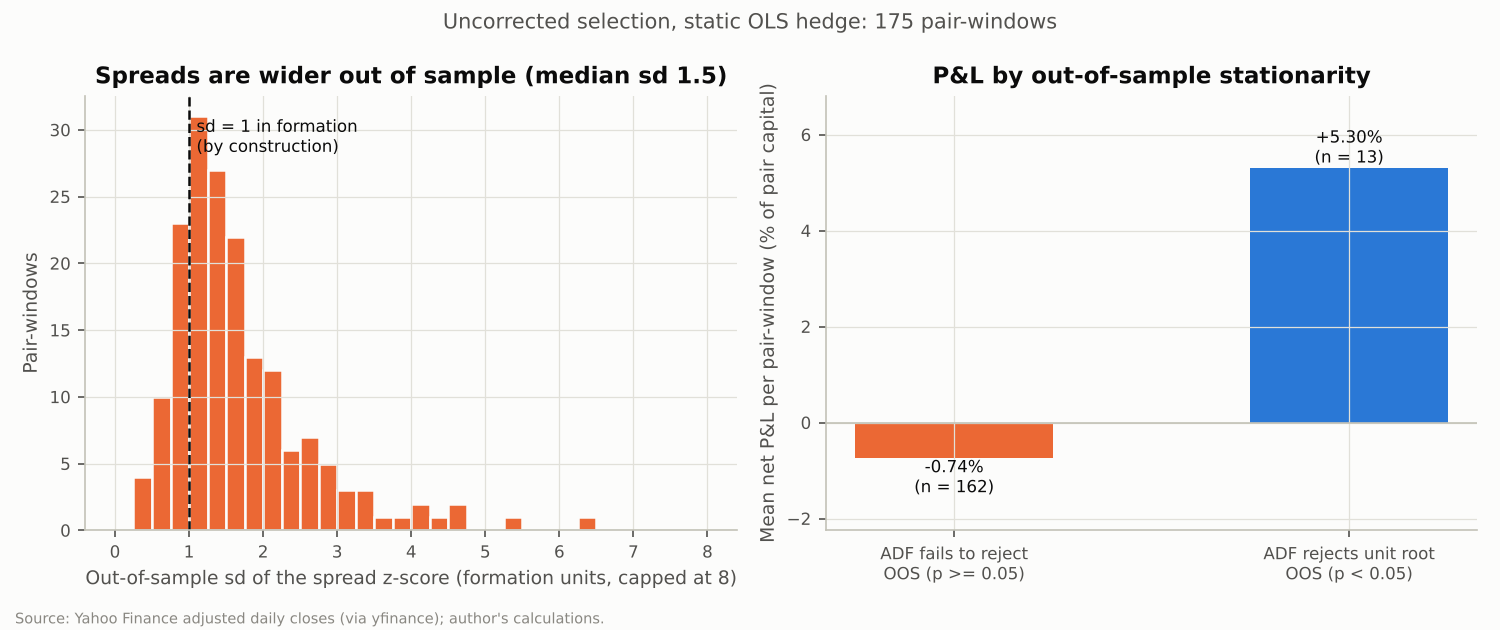

In [12]:
display(Image(FIGURES_DIR / "fig5_breakdown.png"))

Two diagnostics of the *formation* spread out of sample:

- **`pct_oos_adf_reject`** is the share of pair-windows where the ADF test still rejects a unit root. The test has low power on 126 days, and selection biases formation half-lives downward, so failing to reject is not proof of a break.
- **`median_oos_z_sd`** and **`mean_frac_days_beyond_stop`** measure how wide the spread became in formation units, where the sd is 1 by construction.

`median_signal_z_ac1` shows the Kalman prediction errors are strongly autocorrelated (about 0.9): the filter is misspecified for an AR(1) spread.

In [13]:
t = pd.read_csv(RESULTS_DIR / "trades_uncorrected_kalman.csv")
print("Worst Kalman trades (uncorrected selection): large losses closed by the mean-crossing exit, not the stop")
t.nsmallest(5, "net")[["group", "y", "x", "entry_date", "exit_date", "reason", "net", "days"]]

Worst Kalman trades (uncorrected selection): large losses closed by the mean-crossing exit, not the stop


,group,y,x,entry_date,exit_date,reason,net,days
204,semis,INTC,MU,2024-03-22,2024-05-15,exit,-0.426,37
219,semis,TXN,MU,2025-09-11,2025-10-21,exit,-0.366,28
216,semis,ADI,MU,2025-09-15,2025-10-20,exit,-0.309,25
76,semis,MU,LRCX,2015-06-16,2015-06-29,stop,-0.201,9
186,energy,HAL,VLO,2022-01-14,2022-03-21,exit,-0.196,44


## 5. Sensitivity grid (reported, not optimised)

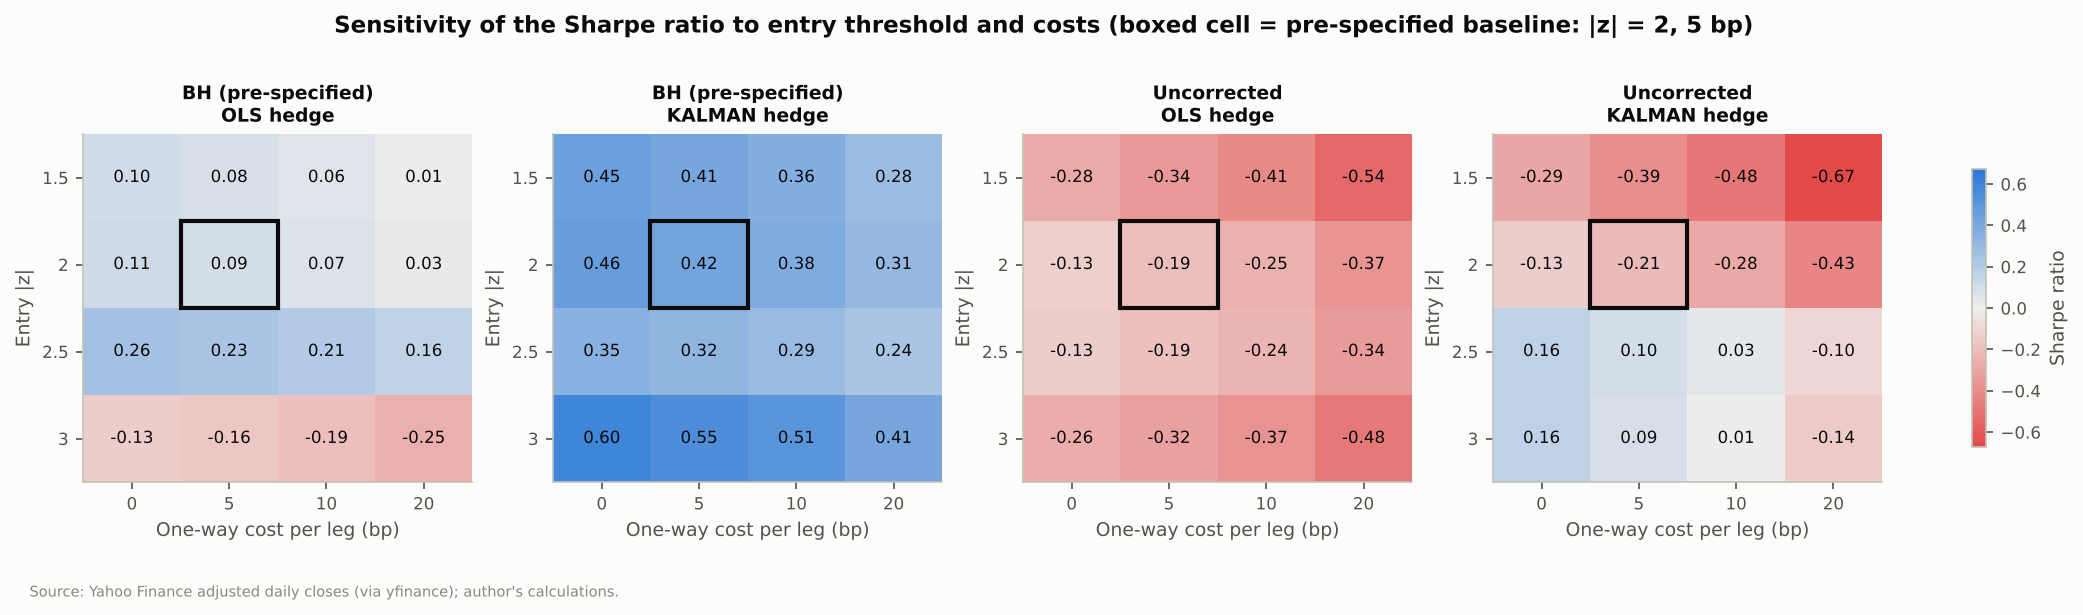

best of 64 cells: {'spec': 'BH (pre-specified)', 'hedge': 'kalman', 'entry_z': np.float64(3.0), 'cost_bps': np.float64(0.0), 'sharpe': np.float64(0.5958900924342598), 'p_value': np.float64(0.04997858851077336), 'n_trades': np.int64(5), 'bonferroni_p': 1.0}


In [14]:
grid = pd.read_csv(RESULTS_DIR / "sensitivity_grid.csv")
display(Image(FIGURES_DIR / "fig4_sensitivity_grid.png"))
print("best of", key["grid_best"]["n_cells"], "cells:", {k: key["grid_best"][k] for k in ["spec", "hedge", "entry_z", "cost_bps", "sharpe", "p_value", "n_trades", "bonferroni_p"]})

In [15]:
pd.read_csv(RESULTS_DIR / "robustness.csv")

,spec,hedge,variant,sharpe,ann_return,p_value,n_trades,n_pair_windows
0,BH (pre-specified),ols,baseline,0.091,0.004,0.661,12,7
1,BH (pre-specified),ols,hedge-ratio weighting (not dollar-neutral),0.138,0.007,0.504,12,7
2,BH (pre-specified),ols,no Johansen confirmation,0.091,0.004,0.661,12,7
3,BH (pre-specified),ols,"no execution lag (same-close fill, optimistic)",0.087,0.003,0.700,12,7
4,BH (pre-specified),kalman,baseline,0.420,0.020,0.076,16,7
5,BH (pre-specified),kalman,hedge-ratio weighting (not dollar-neutral),0.443,0.021,0.059,16,7
6,BH (pre-specified),kalman,no Johansen confirmation,0.420,0.020,0.076,16,7
7,BH (pre-specified),kalman,Kalman delta = 1e-4,0.253,0.011,0.296,11,7
8,BH (pre-specified),kalman,Kalman delta = 1e-2,0.410,0.014,0.171,12,7
9,BH (pre-specified),kalman,"no execution lag (same-close fill, optimistic)",0.315,0.014,0.211,17,7


## 6. Worked example: C vs PNC, trading window January-July 2020

The pair was selected by the pre-specified BH rule. Below, the first entry
signal is recomputed by hand from raw prices and the formation-window
estimates, to show there is nothing hidden in the code.

In [16]:
ex = key["worked_example"]
pd.Series(ex)

y                             C
x                           PNC
formation_start      2019-01-08
formation_end        2020-01-07
trade_start          2020-01-08
trade_end            2020-07-08
alpha                    -0.193
beta                      0.897
spread_std                 0.02
eg_p_yx                     0.0
eg_p_xy                     0.0
johansen                   True
half_life                  3.77
oos_adf_p                 0.529
oos_z_sd                  4.602
net_pnl_ols               0.085
net_pnl_kalman            0.075
n_pairs_in_window             1
dtype: object

In [17]:
y, x = ex["y"], ex["x"]
trades = pd.read_csv(RESULTS_DIR / "worked_example_trades.csv", parse_dates=["entry_date", "exit_date"])
first = trades[trades.hedge == "ols"].iloc[0]
# The fill happens one day after the signal: find the signal day.
i_fill = prices.index.get_loc(first.entry_date)
signal_day = prices.index[i_fill - 1]
ly, lx = np.log(prices.loc[signal_day, y]), np.log(prices.loc[signal_day, x])
form = np.log(prices.loc[ex["formation_start"]:ex["formation_end"], [y, x]])
b, a = np.polyfit(form[x], form[y], 1)          # OLS: log C = a + b log PNC
resid = form[y] - a - b * form[x]
z = (ly - a - b * lx - resid.mean()) / resid.std(ddof=1)
print(f"signal day {signal_day.date()}: log C = {ly:.4f}, log PNC = {lx:.4f}")
print(f"alpha = {a:.4f}, beta = {b:.4f}, spread = {ly - a - b * lx:+.4f}, sd = {resid.std(ddof=1):.4f}")
print(f"z = {z:+.2f}  (>= +2 -> short the spread: short C, long PNC, filled at the next close)")
print(f"pipeline recorded entry_z = {first.entry_z:+.2f}")
trades[["hedge", "entry_date", "exit_date", "direction", "entry_z", "exit_z", "reason", "gross", "costs", "borrow", "net"]]

signal day 2020-01-14: log C = 4.1725, log PNC = 4.8207
alpha = -0.1929, beta = 0.8971, spread = +0.0405, sd = 0.0195
z = +2.07  (>= +2 -> short the spread: short C, long PNC, filled at the next close)
pipeline recorded entry_z = +2.07


,hedge,entry_date,exit_date,direction,entry_z,exit_z,reason,gross,costs,borrow,net
0,ols,2020-01-15,2020-02-25,-1,2.073,-0.865,exit,0.064,0.002,5.172e-04,0.062
1,ols,2020-03-09,2020-03-12,-1,2.655,-1.732,exit,0.117,0.002,6.093e-05,0.115
2,ols,2020-03-16,2020-03-17,1,-3.698,-6.724,stop,-0.090,0.002,1.984e-05,-0.092
3,kalman,2020-01-16,2020-02-03,-1,3.140,-0.254,exit,0.046,0.002,2.114e-04,0.044
4,kalman,2020-03-06,2020-03-12,-1,2.033,-1.524,exit,0.123,0.002,7.091e-05,0.121
5,kalman,2020-03-16,2020-03-18,1,-2.485,-7.292,stop,-0.088,0.002,4.101e-05,-0.090


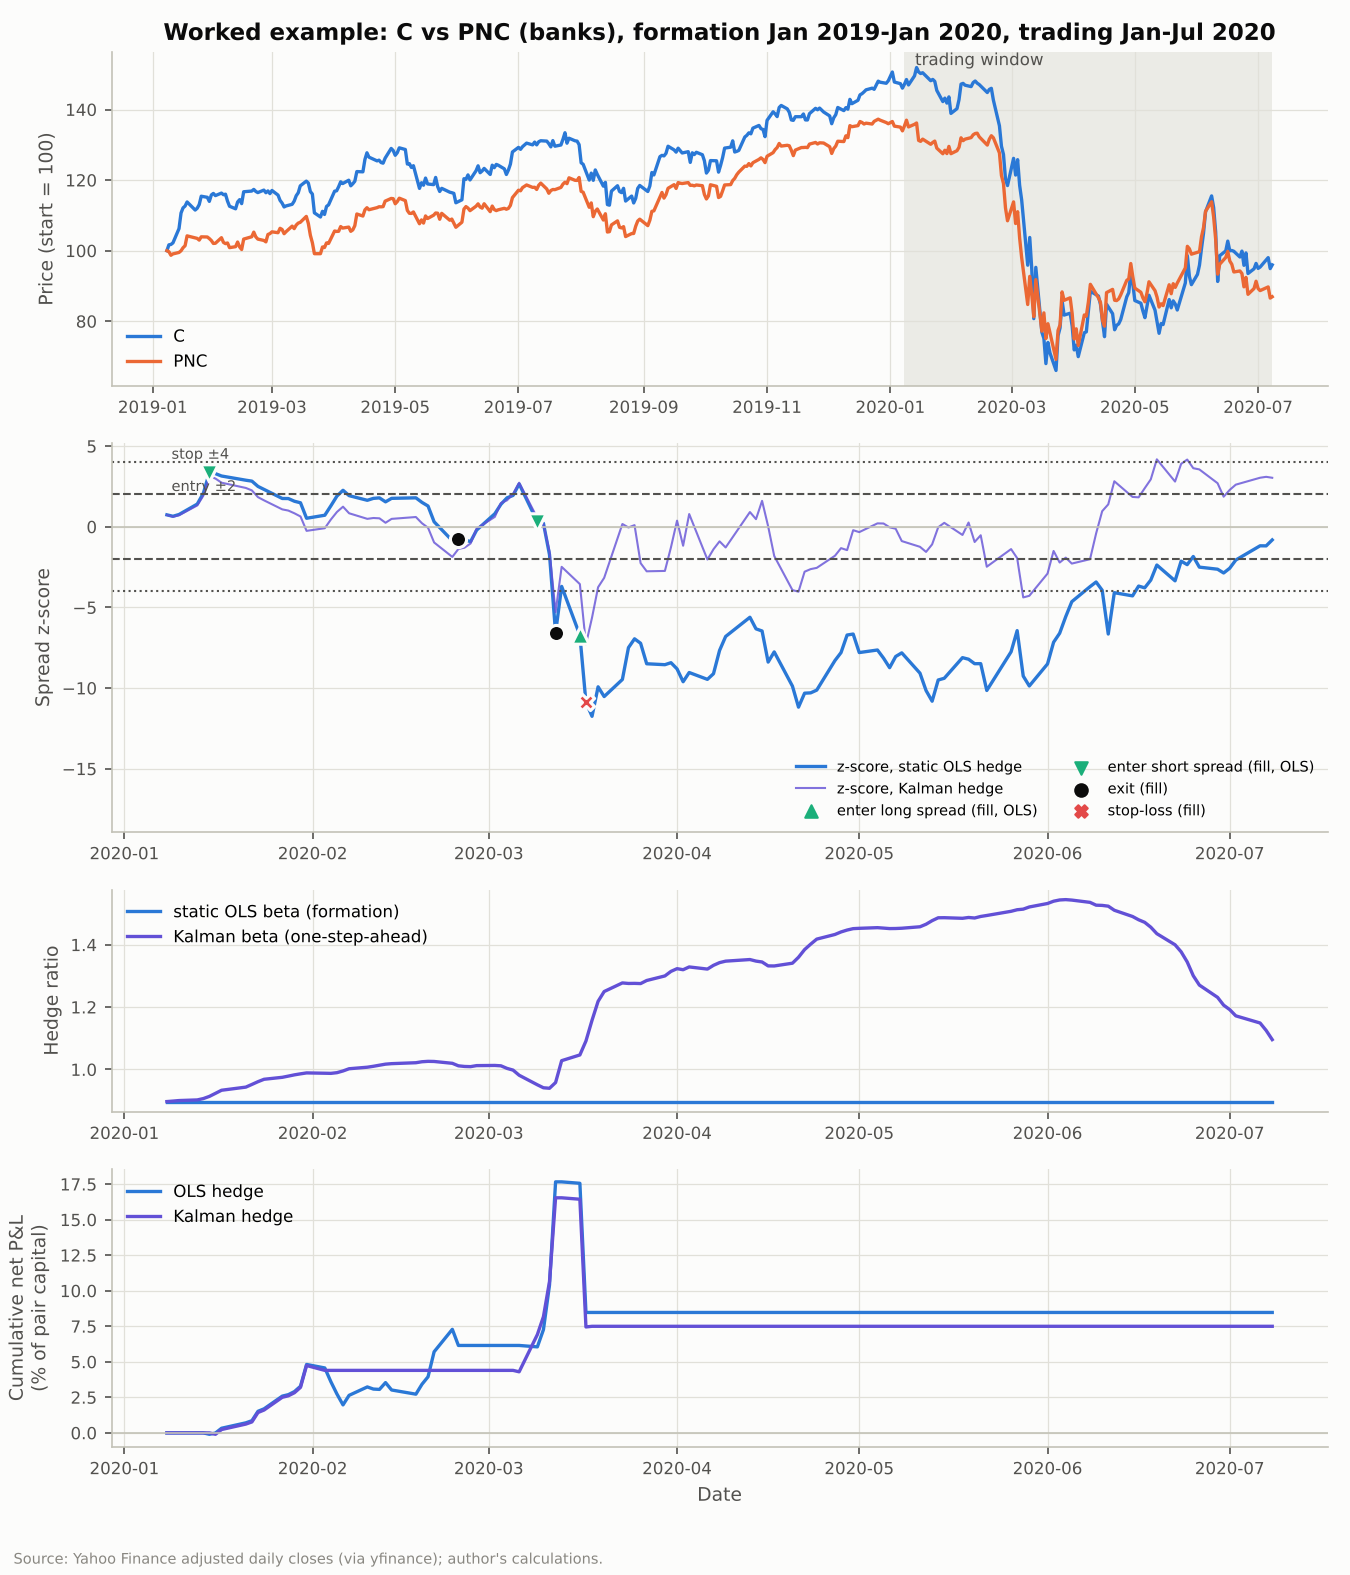

In [18]:
display(Image(FIGURES_DIR / "fig6_worked_example.png"))

**Walk-through (OLS hedge).**
1. *Formation (Jan 2019 - Jan 2020):* log C = -0.19 + 0.90 log PNC; EG p < 0.0001 in both directions, Johansen rejects, half-life 3.8 days. It is the only pair to pass BH in this window.
2. *14 Jan 2020:* z = +2.07 (C rich vs PNC), so short the spread: short $1 of C, long $1 of PNC, filled at the 15 Jan close. The spread converges; the exit signal fills on 25 Feb: **+6.2%** net.
3. *6 Mar:* z = +2.65, so short again, filled Monday 9 Mar. The COVID sell-off then drives the spread straight through its mean to z = -6.6 by 12 Mar: **+11.5%**. This is luck, not the thesis: the spread overshot by six standard deviations.
4. *13 Mar:* z = -3.70 (inside the [-4, -2] band), so buy the spread. It fills on Monday 16 Mar at z = -6.7, already beyond the stop, and the stop fills on 17 Mar at z = -10.9: **-9.2%**.
5. The Kalman hedge ratio drifts from 0.90 to 1.5 during the crisis: the "equilibrium" was not stable. Net for the window: **+8.5%** of pair capital (OLS) and **+7.5%** (Kalman), most of it from one overshoot. Out of sample the spread had an sd of 4.6 formation units (ADF p = 0.53), yet the pair made money. This example was chosen after seeing the results, as an illustration.